In [ ]:
import os

drive_path = "/content/drive/MyDrive"
print(os.listdir(drive_path)[:20])

['Classroom', 'Audio from Krishnendhu.M S (17)', 'Audio from Krishnendhu.M S (16)', 'Audio from Krishnendhu.M S (15)', 'Audio from Krishnendhu.M S (14)', 'Audio from Krishnendhu.M S (13)', 'Audio from Krishnendhu.M S (12)', 'Audio from Krishnendhu.M S (11)', 'Audio from Krishnendhu.M S (10)', 'Audio from Krishnendhu.M S (9)', 'Audio from Krishnendhu.M S (8)', 'Audio from Krishnendhu.M S (7)', 'Audio from Krishnendhu.M S (6)', 'Audio from Krishnendhu.M S (5)', 'Audio from Krishnendhu.M S (4)', 'Audio from Krishnendhu.M S (3)', 'Audio from Krishnendhu.M S (2)', 'Audio from Krishnendhu.M S (1)', 'Audio from Krishnendhu.M S', 'DocScanner 03-Mar-2023 6-51 pm.pdf']


In [ ]:
dataset_folder = "/content/drive/MyDrive/Datasets"
print(os.listdir(dataset_folder))

['CC_LCL-FullData.csv']


In [ ]:

!find "/content/drive/MyDrive" -maxdepth 5 -type f -iname "CC_LCL-FullData.csv" 2>/dev/null


/content/drive/MyDrive/Datasets/CC_LCL-FullData.csv


In [ ]:

%pip install -q pyspark==4.0.1


In [ ]:
from pathlib import Path
from pyspark.sql import functions as F
from pyspark.sql import SparkSession
from pyspark.sql.types import (
    StructType, StructField, StringType
)

RAW_PATH = Path(
    "/content/drive/MyDrive/Datasets/CC_LCL-FullData.csv"
)

spark = (
    SparkSession.builder
    .appName("GridPulse-Direct-Spark")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)


# Keep the new direct-Spark outputs separate from the old batch outputs.
DIRECT_ROOT = Path(
    "/content/drive/MyDrive/GridPulse_outputs/direct_spark_run"
)

DIRECT_SILVER = DIRECT_ROOT / "silver"
DIRECT_QUALITY = DIRECT_ROOT / "quality"

DIRECT_ROOT.mkdir(parents=True, exist_ok=True)
DIRECT_SILVER.mkdir(parents=True, exist_ok=True)
DIRECT_QUALITY.mkdir(parents=True, exist_ok=True)

assert RAW_PATH.exists(), f"CSV not found: {RAW_PATH}"

source_schema = StructType([
    StructField("LCLid", StringType(), True),
    StructField("stdorToU", StringType(), True),
    StructField("DateTime", StringType(), True),
    StructField("KWH/hh (per half hour)", StringType(), True),
])

print("Source file:", RAW_PATH)
print("Spark application:", spark.sparkContext.appName)
print("Spark master:", spark.sparkContext.master)
print("Source size (GiB):", round(RAW_PATH.stat().st_size / 2**30, 2))
print("Direct output folder:", DIRECT_ROOT)
print("Spark version:", spark.version)

Source file: /content/drive/MyDrive/Datasets/CC_LCL-FullData.csv
Spark application: GridPulse-Direct-Spark
Spark master: local[*]
Source size (GiB): 7.96
Direct output folder: /content/drive/MyDrive/GridPulse_outputs/direct_spark_run
Spark version: 4.0.1


In [ ]:
raw_spark_df = (
    spark.read
    .option("header", True)
    .option("mode", "FAILFAST")
    .schema(source_schema)
    .csv(str(RAW_PATH))
)

print("Columns:", raw_spark_df.columns)

raw_spark_df.printSchema()

print("Sample records:")
raw_spark_df.show(5, truncate=False)

Columns: ['LCLid', 'stdorToU', 'DateTime', 'KWH/hh (per half hour)']
root
 |-- LCLid: string (nullable = true)
 |-- stdorToU: string (nullable = true)
 |-- DateTime: string (nullable = true)
 |-- KWH/hh (per half hour): string (nullable = true)

Sample records:
+---------+--------+---------------------------+----------------------+
|LCLid    |stdorToU|DateTime                   |KWH/hh (per half hour)|
+---------+--------+---------------------------+----------------------+
|MAC000002|Std     |2012-10-12 00:30:00.0000000| 0                    |
|MAC000002|Std     |2012-10-12 01:00:00.0000000| 0                    |
|MAC000002|Std     |2012-10-12 01:30:00.0000000| 0                    |
|MAC000002|Std     |2012-10-12 02:00:00.0000000| 0                    |
|MAC000002|Std     |2012-10-12 02:30:00.0000000| 0                    |
+---------+--------+---------------------------+----------------------+
only showing top 5 rows


In [ ]:

from pyspark.sql import functions as F

# Read the original CSV directly using PySpark
raw_spark_df = (
    spark.read
    .option("header", True)
    .option("enforceSchema", True)
    .schema(source_schema)
    .csv(str(RAW_PATH))
)

# Standardize the column names and trim whitespace
df = raw_spark_df.select(
    F.trim(F.col("LCLid")).alias("household_id"),
    F.trim(F.col("stdorToU")).alias("tariff_type"),
    F.trim(F.col("DateTime")).alias("reading_time_raw"),
    F.trim(F.col("KWH/hh (per half hour)")).alias("energy_raw")
)

# Parse timestamps and energy values
parsed_df = (
    df
    .withColumn(
        "reading_time",
        F.try_to_timestamp(
            F.col("reading_time_raw"),
            F.lit("yyyy-MM-dd HH:mm:ss.SSSSSSS")
        )
    )
    .withColumn(
        "energy_kwh_half_hour",
        F.expr("try_cast(energy_raw AS DOUBLE)")
    )
)

# Assign a rejection reason to invalid records
classified_df = parsed_df.withColumn(
    "rejection_reason",
    F.when(
        F.col("household_id").isNull() |
        (F.col("household_id") == ""),
        F.lit("missing_household_id")
    )
    .when(
        F.col("tariff_type").isNull() |
        (F.col("tariff_type") == ""),
        F.lit("missing_tariff_type")
    )
    .when(
        F.col("reading_time").isNull(),
        F.lit("missing_or_invalid_timestamp")
    )
    .when(
        F.col("energy_kwh_half_hour").isNull() |
        F.isnan(F.col("energy_kwh_half_hour")),
        F.lit("missing_or_invalid_energy")
    )
    .when(
        F.col("energy_kwh_half_hour") < 0,
        F.lit("negative_energy_value")
    )
)

# Separate valid and rejected records
clean_df = (
    classified_df
    .filter(F.col("rejection_reason").isNull())
    .select(
        "household_id",
        "tariff_type",
        "reading_time",
        "energy_kwh_half_hour"
    )
)

rejected_df = (
    classified_df
    .filter(F.col("rejection_reason").isNotNull())
    .select(
        "household_id",
        "tariff_type",
        "reading_time_raw",
        "energy_raw",
        "rejection_reason"
    )
)

print("Sample valid records:")
clean_df.show(10, truncate=False)

print("Sample rejected records, if any:")
rejected_df.show(10, truncate=False)


Sample valid records:
+------------+-----------+-------------------+--------------------+
|household_id|tariff_type|reading_time       |energy_kwh_half_hour|
+------------+-----------+-------------------+--------------------+
|MAC000002   |Std        |2012-10-12 00:30:00|0.0                 |
|MAC000002   |Std        |2012-10-12 01:00:00|0.0                 |
|MAC000002   |Std        |2012-10-12 01:30:00|0.0                 |
|MAC000002   |Std        |2012-10-12 02:00:00|0.0                 |
|MAC000002   |Std        |2012-10-12 02:30:00|0.0                 |
|MAC000002   |Std        |2012-10-12 03:00:00|0.0                 |
|MAC000002   |Std        |2012-10-12 03:30:00|0.0                 |
|MAC000002   |Std        |2012-10-12 04:00:00|0.0                 |
|MAC000002   |Std        |2012-10-12 04:30:00|0.0                 |
|MAC000002   |Std        |2012-10-12 05:00:00|0.0                 |
+------------+-----------+-------------------+--------------------+
only showing top 10 rows
S

In [ ]:
from pathlib import Path
import shutil

DIRECT_SILVER = DIRECT_ROOT / "silver"
DIRECT_QUALITY = DIRECT_ROOT / "quality"

clean_path = DIRECT_SILVER / "energy"
quality_path = DIRECT_QUALITY / "rejected"

# Set to True if you want to allow overwriting existing outputs
OVERWRITE = False

# Create output parent directories
DIRECT_SILVER.mkdir(parents=True, exist_ok=True)
DIRECT_QUALITY.mkdir(parents=True, exist_ok=True)

# Protect or handle existing outputs
if clean_path.exists() or quality_path.exists():
    if OVERWRITE:
        print("Overwrite enabled. Deleting existing output directories...")
        if clean_path.exists():
            shutil.rmtree(clean_path)
        if quality_path.exists():
            shutil.rmtree(quality_path)
    else:
        raise FileExistsError(
            "An output directory already exists. Inspect it or set OVERWRITE = True to replace it."
        )

print("Writing clean records to:", clean_path)
clean_df.write \
    .mode("errorifexists") \
    .partitionBy("tariff_type") \
    .parquet(str(clean_path))

print("Clean data saved successfully.")

print("Writing rejected records to:", quality_path)
rejected_df.write \
    .mode("errorifexists") \
    .parquet(str(quality_path))

print("Rejected data saved successfully.")

Overwrite enabled. Deleting existing output directories...
Writing clean records to: /content/drive/MyDrive/GridPulse_outputs/direct_spark_run/silver/energy
Clean data saved successfully.
Writing rejected records to: /content/drive/MyDrive/GridPulse_outputs/direct_spark_run/quality/rejected
Rejected data saved successfully.


In [ ]:
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/GridPulse_outputs/direct_spark_run"
)

paths = {
    "Silver": ROOT / "silver/energy",
    "Rejected data": ROOT / "quality/rejected",
    "Deduplicated Silver": ROOT / "silver/energy_deduplicated",
    "Original Gold hourly": ROOT / "gold/hourly_consumption",
    "Original Gold daily": ROOT / "gold/daily_consumption",
    "Original Gold household": ROOT / "gold/household_summary",
    "Corrected Gold hourly": ROOT / "gold_deduplicated/hourly_consumption",
    "Corrected Gold daily": ROOT / "gold_deduplicated/daily_consumption",
    "Corrected Gold household": ROOT / "gold_deduplicated/household_summary",
}

for name, path in paths.items():
    status = (
        "COMPLETE"
        if path.is_dir() and (path / "_SUCCESS").exists()
        else "EXISTS - CHECK"
        if path.exists()
        else "MISSING"
    )
    print(f"{name}: {status}")

Silver: COMPLETE
Rejected data: COMPLETE
Deduplicated Silver: COMPLETE
Original Gold hourly: COMPLETE
Original Gold daily: COMPLETE
Original Gold household: COMPLETE
Corrected Gold hourly: COMPLETE
Corrected Gold daily: COMPLETE
Corrected Gold household: MISSING


In [ ]:
from pathlib import Path
from pyspark.sql import functions as F

ROOT = Path(
    "/content/drive/MyDrive/GridPulse_outputs/direct_spark_run"
)

DEDUP_SILVER_PATH = ROOT / "silver" / "energy_deduplicated"
HOUSEHOLD_PATH = ROOT / "gold_deduplicated" / "household_summary"

# Read the saved deduplicated Silver data
dedup_silver_df = spark.read.parquet(str(DEDUP_SILVER_PATH))

# Build the corrected household summary
household_dedup_df = (
    dedup_silver_df
    .groupBy("household_id")
    .agg(
        F.sum("energy_kwh_half_hour").alias("total_energy_kwh"),
        F.avg("energy_kwh_half_hour").alias("average_half_hour_kwh"),
        F.max("energy_kwh_half_hour").alias("peak_half_hour_kwh"),
        F.count("*").alias("total_readings"),
        F.min("reading_time").alias("first_reading"),
        F.max("reading_time").alias("last_reading")
    )
)

# Prevent accidental overwriting
if HOUSEHOLD_PATH.exists():
    raise FileExistsError(
        f"Output already exists: {HOUSEHOLD_PATH}. Check it before proceeding."
    )

household_dedup_df.write \
    .mode("errorifexists") \
    .parquet(str(HOUSEHOLD_PATH))

print("Corrected household summary saved successfully.")

Corrected household summary saved successfully.


In [ ]:

saved_clean_df = spark.read.parquet(str(clean_path))
saved_rejected_df = spark.read.parquet(str(quality_path))

print("Clean output schema:")
saved_clean_df.printSchema()

print("Rejected output schema:")
saved_rejected_df.printSchema()

print("Sample clean records:")
saved_clean_df.show(5, truncate=False)

print("Sample rejected records:")
saved_rejected_df.show(5, truncate=False)


Clean output schema:
root
 |-- household_id: string (nullable = true)
 |-- reading_time: timestamp (nullable = true)
 |-- energy_kwh_half_hour: double (nullable = true)
 |-- tariff_type: string (nullable = true)

Rejected output schema:
root
 |-- household_id: string (nullable = true)
 |-- tariff_type: string (nullable = true)
 |-- reading_time_raw: string (nullable = true)
 |-- energy_raw: string (nullable = true)
 |-- rejection_reason: string (nullable = true)

Sample clean records:
+------------+-------------------+--------------------+-----------+
|household_id|reading_time       |energy_kwh_half_hour|tariff_type|
+------------+-------------------+--------------------+-----------+
|MAC004876   |2012-03-10 19:00:00|1.7869999           |Std        |
|MAC004951   |2013-08-14 06:30:00|0.272               |Std        |
|MAC004876   |2012-03-10 19:30:00|0.745               |Std        |
|MAC004951   |2013-08-14 07:00:00|0.045               |Std        |
|MAC004876   |2012-03-10 20:00:00|

In [ ]:

# Count the saved Parquet records
clean_count = saved_clean_df.count()
rejected_count = saved_rejected_df.count()

print("=" * 50)
print("GRIDPULSE DATA QUALITY SUMMARY")
print("=" * 50)
print(f"Clean records:    {clean_count:,}")
print(f"Rejected records: {rejected_count:,}")
print(f"Total processed:  {clean_count + rejected_count:,}")

if clean_count + rejected_count > 0:
    rejection_rate = rejected_count / (clean_count + rejected_count) * 100
    print(f"Rejection rate:   {rejection_rate:.4f}%")

print("\nRejection reasons:")
saved_rejected_df.groupBy("rejection_reason") \
    .count() \
    .orderBy(F.desc("count")) \
    .show(truncate=False)


GRIDPULSE DATA QUALITY SUMMARY
Clean records:    167,926,914
Rejected records: 5,560
Total processed:  167,932,474
Rejection rate:   0.0033%

Rejection reasons:
+-------------------------+-----+
|rejection_reason         |count|
+-------------------------+-----+
|missing_or_invalid_energy|5560 |
+-------------------------+-----+



In [ ]:

from pathlib import Path
from pyspark.sql import functions as F

# Location of your existing Silver data
SILVER_PATH = Path(
    "/content/drive/MyDrive/GridPulse_outputs/"
    "direct_spark_run/silver/energy"
)

# Check that the output exists
assert SILVER_PATH.exists(), (
    f"Silver data not found: {SILVER_PATH}"
)

# Read the saved Parquet data
silver_df = spark.read.parquet(str(SILVER_PATH))

print("Silver data schema:")
silver_df.printSchema()

print("Sample records:")
silver_df.show(5, truncate=False)

print("Available tariff types:")
silver_df.select("tariff_type").distinct().show()


Silver data schema:
root
 |-- household_id: string (nullable = true)
 |-- reading_time: timestamp (nullable = true)
 |-- energy_kwh_half_hour: double (nullable = true)
 |-- tariff_type: string (nullable = true)

Sample records:
+------------+-------------------+--------------------+-----------+
|household_id|reading_time       |energy_kwh_half_hour|tariff_type|
+------------+-------------------+--------------------+-----------+
|MAC004876   |2012-03-10 19:00:00|1.7869999           |Std        |
|MAC004951   |2013-08-14 06:30:00|0.272               |Std        |
|MAC004876   |2012-03-10 19:30:00|0.745               |Std        |
|MAC004951   |2013-08-14 07:00:00|0.045               |Std        |
|MAC004876   |2012-03-10 20:00:00|0.175               |Std        |
+------------+-------------------+--------------------+-----------+
only showing top 5 rows
Available tariff types:
+-----------+
|tariff_type|
+-----------+
|        ToU|
|        Std|
+-----------+



# Create the Gold layer

In [ ]:

from pathlib import Path
from pyspark.sql import functions as F

# Input: existing Silver layer
SILVER_PATH = Path(
    "/content/drive/MyDrive/GridPulse_outputs/"
    "direct_spark_run/silver/energy"
)

# Output: new Gold layer
GOLD_ROOT = Path(
    "/content/drive/MyDrive/GridPulse_outputs/"
    "direct_spark_run/gold"
)

HOURLY_PATH = GOLD_ROOT / "hourly_consumption"
DAILY_PATH = GOLD_ROOT / "daily_consumption"
HOUSEHOLD_PATH = GOLD_ROOT / "household_summary"

# Check inputs and avoid overwriting previous results
assert SILVER_PATH.exists(), "Silver data not found."

for path in [HOURLY_PATH, DAILY_PATH, HOUSEHOLD_PATH]:
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}. Inspect it before rerunning."
        )

GOLD_ROOT.mkdir(parents=True, exist_ok=True)

silver_df = spark.read.parquet(str(SILVER_PATH))

# 1. HOURLY CONSUMPTION
# Sum the half-hour energy readings within each hour.
hourly_df = (
    silver_df
    .withColumn("hour", F.date_trunc("hour", F.col("reading_time")))
    .groupBy("household_id", "hour", "tariff_type")
    .agg(
        F.sum("energy_kwh_half_hour").alias("total_energy_kwh"),
        F.avg("energy_kwh_half_hour").alias("average_half_hour_kwh"),
        F.count("*").alias("reading_count"),
        F.max("energy_kwh_half_hour").alias("peak_half_hour_kwh")
    )
)

# 2. DAILY CONSUMPTION
daily_df = (
    silver_df
    .withColumn("date", F.to_date("reading_time"))
    .groupBy("household_id", "date", "tariff_type")
    .agg(
        F.sum("energy_kwh_half_hour").alias("total_energy_kwh"),
        F.avg("energy_kwh_half_hour").alias("average_half_hour_kwh"),
        F.count("*").alias("reading_count"),
        F.max("energy_kwh_half_hour").alias("peak_half_hour_kwh")
    )
)

# 3. HOUSEHOLD SUMMARY
household_df = (
    silver_df
    .groupBy("household_id")
    .agg(
        F.sum("energy_kwh_half_hour").alias("total_energy_kwh"),
        F.avg("energy_kwh_half_hour").alias("average_half_hour_kwh"),
        F.max("energy_kwh_half_hour").alias("peak_half_hour_kwh"),
        F.count("*").alias("total_readings"),
        F.min("reading_time").alias("first_reading"),
        F.max("reading_time").alias("last_reading")
    )
)

print("Gold transformations created.")
print("Hourly schema:")
hourly_df.printSchema()

print("Daily schema:")
daily_df.printSchema()

print("Household summary schema:")
household_df.printSchema()


FileExistsError: Output already exists: /content/drive/MyDrive/GridPulse_outputs/direct_spark_run/gold/hourly_consumption. Inspect it before rerunning.

# Save the Gold datasets

In [ ]:

hourly_df.write.mode("errorifexists").parquet(str(HOURLY_PATH))
print("Hourly consumption saved.")

daily_df.write.mode("errorifexists").parquet(str(DAILY_PATH))
print("Daily consumption saved.")

household_df.write.mode("errorifexists").parquet(str(HOUSEHOLD_PATH))
print("Household summary saved.")

print("\nGold layer saved to:", GOLD_ROOT)


NameError: name 'hourly_df' is not defined

# Validate the results

In [ ]:

saved_hourly = spark.read.parquet(str(HOURLY_PATH))
saved_daily = spark.read.parquet(str(DAILY_PATH))
saved_household = spark.read.parquet(str(HOUSEHOLD_PATH))

print("Hourly sample:")
saved_hourly.show(5, truncate=False)

print("Daily sample:")
saved_daily.show(5, truncate=False)

print("Household summary sample:")
saved_household.show(5, truncate=False)


# Check incomplete hourly and daily periods

In [ ]:

from pyspark.sql import functions as F

# Read the existing Gold outputs
hourly_df = spark.read.parquet(str(HOURLY_PATH))
daily_df = spark.read.parquet(str(DAILY_PATH))

print("Hourly reading-count distribution:")
hourly_df.groupBy("reading_count") \
    .count() \
    .orderBy("reading_count") \
    .show(20, truncate=False)

print("Daily reading-count distribution:")
daily_df.groupBy("reading_count") \
    .count() \
    .orderBy("reading_count") \
    .show(30, truncate=False)

# Count incomplete periods
incomplete_hours = hourly_df.filter(F.col("reading_count") != 2).count()
incomplete_days = daily_df.filter(F.col("reading_count") != 48).count()

print(f"Hourly groups without exactly 2 readings: {incomplete_hours:,}")
print(f"Daily groups without exactly 48 readings: {incomplete_days:,}")


# Investigate the three-reading hours

In [ ]:

# Find hourly groups containing three readings
three_reading_hours = (
    hourly_df
    .filter(F.col("reading_count") == 3)
    .select("household_id", "hour", "tariff_type")
    .limit(10)
)

print("Example hourly groups with 3 readings:")
three_reading_hours.show(truncate=False)

# Inspect the original Silver records for these groups
sample_groups = three_reading_hours.withColumn(
    "hour_key", F.col("hour")
)

silver_with_hour = silver_df.withColumn(
    "hour_key", F.date_trunc("hour", F.col("reading_time"))
)

details = (
    silver_with_hour.alias("s")
    .join(
        sample_groups.alias("g"),
        (F.col("s.household_id") == F.col("g.household_id")) &
        (F.col("s.tariff_type") == F.col("g.tariff_type")) &
        (F.col("s.hour_key") == F.col("g.hour_key")),
        "inner"
    )
    .select(
        F.col("s.household_id"),
        F.col("s.tariff_type"),
        F.col("s.reading_time"),
        F.col("s.energy_kwh_half_hour")
    )
    .orderBy("household_id", "reading_time")
)

print("Underlying readings:")
details.show(50, truncate=False)


# Measure the duplicates

In [ ]:

from pyspark.sql import functions as F

# Identify repeated records across all four Silver columns
duplicate_groups = (
    silver_df
    .groupBy(
        "household_id",
        "reading_time",
        "energy_kwh_half_hour",
        "tariff_type"
    )
    .count()
    .filter(F.col("count") > 1)
)

print("Number of duplicate groups:")
print(duplicate_groups.count())

print("Total extra duplicate rows:")
duplicate_groups.select(
    F.sum(F.col("count") - 1).alias("extra_duplicate_rows")
).show()

print("Examples:")
duplicate_groups.orderBy(F.desc("count")).show(10, truncate=False)


# Create a deduplicated Silver dataset

In [ ]:
from pathlib import Path
from pyspark.sql import functions as F

# New output path — do not overwrite the original Silver data
DEDUP_SILVER_PATH = (
    Path("/content/drive/MyDrive/GridPulse_outputs/direct_spark_run")
    / "silver"
    / "energy_deduplicated"
)

# Remove only records that match across all four columns
dedup_silver_df = silver_df.dropDuplicates([
    "household_id",
    "reading_time",
    "energy_kwh_half_hour",
    "tariff_type"
])

# Save the corrected Silver dataset
dedup_silver_df.write \
    .mode("errorifexists") \
    .partitionBy("tariff_type") \
    .parquet(str(DEDUP_SILVER_PATH))

print("Deduplicated Silver dataset saved successfully.")
print("Output path:", DEDUP_SILVER_PATH)

# Verify the results


In [ ]:
original_count = silver_df.count()
deduplicated_count = dedup_silver_df.count()

print("Original Silver rows:", original_count)
print("Deduplicated Silver rows:", deduplicated_count)
print("Rows removed:", original_count - deduplicated_count)

print("\nRemaining exact duplicate groups:")

remaining_duplicates = (
    dedup_silver_df
    .groupBy(
        "household_id",
        "reading_time",
        "energy_kwh_half_hour",
        "tariff_type"
    )
    .count()
    .filter(F.col("count") > 1)
)

remaining_duplicates.show(5, truncate=False)

In [ ]:
from pyspark.sql import functions as F
from pathlib import Path

# Use the corrected Silver dataset
silver_clean_df = dedup_silver_df

# Create a separate location for corrected Gold outputs
GOLD_DEDUP_ROOT = Path(
    "/content/drive/MyDrive/GridPulse_outputs/direct_spark_run/gold_deduplicated"
)

HOURLY_DEDUP_PATH = GOLD_DEDUP_ROOT / "hourly_consumption"
DAILY_DEDUP_PATH = GOLD_DEDUP_ROOT / "daily_consumption"
HOUSEHOLD_DEDUP_PATH = GOLD_DEDUP_ROOT / "household_summary"

# 1. Hourly consumption
hourly_dedup_df = (
    silver_clean_df
    .withColumn("hour", F.date_trunc("hour", F.col("reading_time")))
    .groupBy("household_id", "hour", "tariff_type")
    .agg(
        F.sum("energy_kwh_half_hour").alias("total_energy_kwh"),
        F.avg("energy_kwh_half_hour").alias("average_half_hour_kwh"),
        F.count("*").alias("reading_count"),
        F.max("energy_kwh_half_hour").alias("peak_half_hour_kwh")
    )
)

# 2. Daily consumption
daily_dedup_df = (
    silver_clean_df
    .withColumn("date", F.to_date("reading_time"))
    .groupBy("household_id", "date", "tariff_type")
    .agg(
        F.sum("energy_kwh_half_hour").alias("total_energy_kwh"),
        F.avg("energy_kwh_half_hour").alias("average_half_hour_kwh"),
        F.count("*").alias("reading_count"),
        F.max("energy_kwh_half_hour").alias("peak_half_hour_kwh")
    )
)

# 3. Household summary
household_dedup_df = (
    silver_clean_df
    .groupBy("household_id")
    .agg(
        F.sum("energy_kwh_half_hour").alias("total_energy_kwh"),
        F.avg("energy_kwh_half_hour").alias("average_half_hour_kwh"),
        F.max("energy_kwh_half_hour").alias("peak_half_hour_kwh"),
        F.count("*").alias("total_readings"),
        F.min("reading_time").alias("first_reading"),
        F.max("reading_time").alias("last_reading")
    )
)

# Save all three outputs without overwriting existing data
hourly_dedup_df.write.mode("errorifexists").parquet(str(HOURLY_DEDUP_PATH))
daily_dedup_df.write.mode("errorifexists").parquet(str(DAILY_DEDUP_PATH))
household_dedup_df.write.mode("errorifexists").parquet(str(HOUSEHOLD_DEDUP_PATH))

print("All corrected Gold tables saved successfully.")
print("Hourly:", HOURLY_DEDUP_PATH)
print("Daily:", DAILY_DEDUP_PATH)
print("Household summary:", HOUSEHOLD_DEDUP_PATH)

AnalysisException: [PATH_ALREADY_EXISTS] Path file:/content/drive/MyDrive/GridPulse_outputs/direct_spark_run/gold_deduplicated/hourly_consumption already exists. Set mode as "overwrite" to overwrite the existing path. SQLSTATE: 42K04

In [ ]:
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/GridPulse_outputs/direct_spark_run"
)

paths = {
    "Corrected hourly": ROOT / "gold_deduplicated/hourly_consumption",
    "Corrected daily": ROOT / "gold_deduplicated/daily_consumption",
    "Corrected household": ROOT / "gold_deduplicated/household_summary",
}

for name, path in paths.items():
    success = path.is_dir() and (path / "_SUCCESS").exists()
    print(f"{name}: {'COMPLETE' if success else 'CHECK NEEDED'}")

Corrected hourly: COMPLETE
Corrected daily: COMPLETE
Corrected household: COMPLETE


In [ ]:
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/GridPulse_outputs/direct_spark_run"
)

hourly_df = spark.read.parquet(
    str(ROOT / "gold_deduplicated/hourly_consumption")
)

daily_df = spark.read.parquet(
    str(ROOT / "gold_deduplicated/daily_consumption")
)

household_df = spark.read.parquet(
    str(ROOT / "gold_deduplicated/household_summary")
)

print("Hourly Gold schema:")
hourly_df.printSchema()

print("\nDaily Gold schema:")
daily_df.printSchema()

print("\nHousehold Gold schema:")
household_df.printSchema()

print("\nAll three corrected Gold tables loaded successfully.")

Hourly Gold schema:
root
 |-- household_id: string (nullable = true)
 |-- hour: timestamp (nullable = true)
 |-- tariff_type: string (nullable = true)
 |-- total_energy_kwh: double (nullable = true)
 |-- average_half_hour_kwh: double (nullable = true)
 |-- reading_count: long (nullable = true)
 |-- peak_half_hour_kwh: double (nullable = true)


Daily Gold schema:
root
 |-- household_id: string (nullable = true)
 |-- date: date (nullable = true)
 |-- tariff_type: string (nullable = true)
 |-- total_energy_kwh: double (nullable = true)
 |-- average_half_hour_kwh: double (nullable = true)
 |-- reading_count: long (nullable = true)
 |-- peak_half_hour_kwh: double (nullable = true)


Household Gold schema:
root
 |-- household_id: string (nullable = true)
 |-- total_energy_kwh: double (nullable = true)
 |-- average_half_hour_kwh: double (nullable = true)
 |-- peak_half_hour_kwh: double (nullable = true)
 |-- total_readings: long (nullable = true)
 |-- first_reading: timestamp (nullable = tru

In [ ]:
from pyspark.sql import functions as F

hourly_features_df = (
    hourly_df
    .withColumn("hour_of_day", F.hour("hour"))
    .withColumn("day_of_week", F.dayofweek("hour"))
    .withColumn(
        "is_weekend",
        F.dayofweek("hour").isin([1, 7])
    )
    .withColumn("month", F.month("hour"))
    .withColumn(
        "is_peak_hour",
        F.hour("hour").between(17, 20)
    )
)

print("Hourly feature engineering completed.")
hourly_features_df.printSchema()

hourly_features_df.select(
    "household_id",
    "hour",
    "total_energy_kwh",
    "hour_of_day",
    "day_of_week",
    "is_weekend",
    "month",
    "is_peak_hour"
).show(10, truncate=False)

Hourly feature engineering completed.
root
 |-- household_id: string (nullable = true)
 |-- hour: timestamp (nullable = true)
 |-- tariff_type: string (nullable = true)
 |-- total_energy_kwh: double (nullable = true)
 |-- average_half_hour_kwh: double (nullable = true)
 |-- reading_count: long (nullable = true)
 |-- peak_half_hour_kwh: double (nullable = true)
 |-- hour_of_day: integer (nullable = true)
 |-- day_of_week: integer (nullable = true)
 |-- is_weekend: boolean (nullable = true)
 |-- month: integer (nullable = true)
 |-- is_peak_hour: boolean (nullable = true)

+------------+-------------------+-------------------+-----------+-----------+----------+-----+------------+
|household_id|hour               |total_energy_kwh   |hour_of_day|day_of_week|is_weekend|month|is_peak_hour|
+------------+-------------------+-------------------+-----------+-----------+----------+-----+------------+
|MAC000002   |2012-10-12 17:00:00|0.847              |17         |6          |false     |10   |

In [ ]:
from pathlib import Path

FEATURE_PATH = Path(
    "/content/drive/MyDrive/GridPulse_outputs/"
    "direct_spark_run/features/hourly_features"
)

# Protect existing results
if FEATURE_PATH.exists():
    raise FileExistsError(
        f"Feature output already exists: {FEATURE_PATH}. "
        "Check it before rerunning."
    )

hourly_features_df.write \
    .mode("errorifexists") \
    .parquet(str(FEATURE_PATH))

print("Hourly features saved successfully.")
print("Output path:", FEATURE_PATH)

Hourly features saved successfully.
Output path: /content/drive/MyDrive/GridPulse_outputs/direct_spark_run/features/hourly_features


In [ ]:
from pyspark.sql import functions as F
from pathlib import Path

# Create daily features from the corrected Gold table
daily_features_df = (
    daily_df
    .withColumn("day_of_week", F.dayofweek("date"))
    .withColumn(
        "is_weekend",
        F.dayofweek("date").isin([1, 7])
    )
    .withColumn("month", F.month("date"))
    .withColumn("year", F.year("date"))
    .withColumn("day_of_month", F.dayofmonth("date"))
)

print("Daily feature engineering completed.")

daily_features_df.printSchema()

daily_features_df.select(
    "household_id",
    "date",
    "total_energy_kwh",
    "day_of_week",
    "is_weekend",
    "month",
    "year"
).show(10, truncate=False)

Daily feature engineering completed.
root
 |-- household_id: string (nullable = true)
 |-- date: date (nullable = true)
 |-- tariff_type: string (nullable = true)
 |-- total_energy_kwh: double (nullable = true)
 |-- average_half_hour_kwh: double (nullable = true)
 |-- reading_count: long (nullable = true)
 |-- peak_half_hour_kwh: double (nullable = true)
 |-- day_of_week: integer (nullable = true)
 |-- is_weekend: boolean (nullable = true)
 |-- month: integer (nullable = true)
 |-- year: integer (nullable = true)
 |-- day_of_month: integer (nullable = true)

+------------+----------+------------------+-----------+----------+-----+----+
|household_id|date      |total_energy_kwh  |day_of_week|is_weekend|month|year|
+------------+----------+------------------+-----------+----------+-----+----+
|MAC004876   |2012-03-12|27.250999999999994|2          |false     |3    |2012|
|MAC004951   |2013-08-29|2.918             |5          |false     |8    |2013|
|MAC004951   |2013-08-30|3.222          

In [ ]:
from pathlib import Path

DAILY_FEATURE_PATH = Path(
    "/content/drive/MyDrive/GridPulse_outputs/"
    "direct_spark_run/features/daily_features"
)

if DAILY_FEATURE_PATH.exists():
    raise FileExistsError(
        f"Output already exists: {DAILY_FEATURE_PATH}. "
        "Check it before rerunning."
    )

daily_features_df.write \
    .mode("errorifexists") \
    .parquet(str(DAILY_FEATURE_PATH))

print("Daily features saved successfully.")
print("Output path:", DAILY_FEATURE_PATH)

Daily features saved successfully.
Output path: /content/drive/MyDrive/GridPulse_outputs/direct_spark_run/features/daily_features


In [ ]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Order each household's daily records chronologically
daily_window = (
    Window
    .partitionBy("household_id", "tariff_type")
    .orderBy("date")
)

# Previous observation and previous 7 observations only
rolling_window = daily_window.rowsBetween(-7, -1)

forecast_features_df = (
    daily_df
    .withColumn(
        "previous_observation_date",
        F.lag("date", 1).over(daily_window)
    )
    .withColumn(
        "previous_day_consumption_kwh",
        F.lag("total_energy_kwh", 1).over(daily_window)
    )
    .withColumn(
        "days_since_previous_observation",
        F.datediff("date", F.col("previous_observation_date"))
    )
    .withColumn(
        "consumption_change_kwh",
        F.col("total_energy_kwh")
        - F.col("previous_day_consumption_kwh")
    )
    .withColumn(
        "previous_7_observation_avg_kwh",
        F.avg("total_energy_kwh").over(rolling_window)
    )
)

print("Forecasting features created.")
forecast_features_df.printSchema()

forecast_features_df.select(
    "household_id",
    "tariff_type",
    "date",
    "total_energy_kwh",
    "previous_observation_date",
    "days_since_previous_observation",
    "previous_day_consumption_kwh",
    "consumption_change_kwh",
    "previous_7_observation_avg_kwh"
).show(10, truncate=False)

Forecasting features created.
root
 |-- household_id: string (nullable = true)
 |-- date: date (nullable = true)
 |-- tariff_type: string (nullable = true)
 |-- total_energy_kwh: double (nullable = true)
 |-- average_half_hour_kwh: double (nullable = true)
 |-- reading_count: long (nullable = true)
 |-- peak_half_hour_kwh: double (nullable = true)
 |-- previous_observation_date: date (nullable = true)
 |-- previous_day_consumption_kwh: double (nullable = true)
 |-- days_since_previous_observation: integer (nullable = true)
 |-- consumption_change_kwh: double (nullable = true)
 |-- previous_7_observation_avg_kwh: double (nullable = true)

+------------+-----------+----------+------------------+-------------------------+-------------------------------+----------------------------+----------------------+------------------------------+
|household_id|tariff_type|date      |total_energy_kwh  |previous_observation_date|days_since_previous_observation|previous_day_consumption_kwh|consumption_c

In [ ]:
from pathlib import Path

FORECAST_FEATURE_PATH = Path(
    "/content/drive/MyDrive/GridPulse_outputs/"
    "direct_spark_run/features/forecast_features"
)

if FORECAST_FEATURE_PATH.exists():
    raise FileExistsError(
        f"Output already exists: {FORECAST_FEATURE_PATH}. "
        "Check it before rerunning."
    )

forecast_features_df.write \
    .mode("errorifexists") \
    .parquet(str(FORECAST_FEATURE_PATH))

print("Forecasting features saved successfully.")
print("Output path:", FORECAST_FEATURE_PATH)

Forecasting features saved successfully.
Output path: /content/drive/MyDrive/GridPulse_outputs/direct_spark_run/features/forecast_features


In [ ]:
from pathlib import Path

SILVER_PATH = Path(
    "/content/drive/MyDrive/GridPulse_outputs/"
    "direct_spark_run/silver/energy_deduplicated"
)

print("Silver path exists:", SILVER_PATH.exists())

benchmark_df = spark.read.parquet(str(SILVER_PATH))

print("Columns:", benchmark_df.columns)
benchmark_df.printSchema()

Silver path exists: True
Columns: ['household_id', 'reading_time', 'energy_kwh_half_hour', 'tariff_type']
root
 |-- household_id: string (nullable = true)
 |-- reading_time: timestamp (nullable = true)
 |-- energy_kwh_half_hour: double (nullable = true)
 |-- tariff_type: string (nullable = true)



In [ ]:
import time
from pyspark.sql import functions as F

# Use the saved deduplicated Silver data
benchmark_df = spark.read.parquet(
    "/content/drive/MyDrive/GridPulse_outputs/"
    "direct_spark_run/silver/energy_deduplicated"
)

# Prepare a 1-million-row test dataset
sample_df = benchmark_df.limit(1_000_000)

# Start timing before the Spark action
start_time = time.time()

result = (
    sample_df
    .groupBy("tariff_type")
    .agg(
        F.count("*").alias("row_count"),
        F.sum("energy_kwh_half_hour").alias("total_energy_kwh"),
        F.avg("energy_kwh_half_hour").alias("average_energy_kwh")
    )
)

# Trigger execution
result.show()

elapsed_seconds = time.time() - start_time

# Count the sample for throughput calculation
sample_count = sample_df.count()

print(f"Rows processed: {sample_count:,}")
print(f"Elapsed time: {elapsed_seconds:.2f} seconds")
print(
    f"Approximate throughput: "
    f"{sample_count / elapsed_seconds:,.0f} rows/second"
)

+-----------+---------+----------------+------------------+
|tariff_type|row_count|total_energy_kwh|average_energy_kwh|
+-----------+---------+----------------+------------------+
|        Std|  1000000|223634.551985013| 0.223634551985013|
+-----------+---------+----------------+------------------+

Rows processed: 1,000,000
Elapsed time: 3.02 seconds
Approximate throughput: 330,899 rows/second


In [ ]:
import time
from pyspark.sql import functions as F

benchmark_df = spark.read.parquet(
    "/content/drive/MyDrive/GridPulse_outputs/"
    "direct_spark_run/silver/energy_deduplicated"
)

# Test 10 million rows
sample_df = benchmark_df.limit(10_000_000)

# Define the aggregation before starting the timer
result = (
    sample_df
    .groupBy("tariff_type")
    .agg(
        F.count("*").alias("row_count"),
        F.sum("energy_kwh_half_hour").alias("total_energy_kwh"),
        F.avg("energy_kwh_half_hour").alias("average_energy_kwh")
    )
)

start_time = time.perf_counter()

# collect() triggers the aggregation
results = result.collect()

elapsed_seconds = time.perf_counter() - start_time

print("10-million-row benchmark")
print("Results:", results)
print(f"Elapsed time: {elapsed_seconds:.2f} seconds")
print(
    f"Approximate throughput: "
    f"{10_000_000 / elapsed_seconds:,.0f} rows/second"
)

10-million-row benchmark
Results: [Row(tariff_type='Std', row_count=10000000, total_energy_kwh=2115539.0659358576, average_energy_kwh=0.21155390659358575)]
Elapsed time: 16.45 seconds
Approximate throughput: 608,009 rows/second


In [ ]:
import time
from pyspark.sql import functions as F

benchmark_df = spark.read.parquet(
    "/content/drive/MyDrive/GridPulse_outputs/"
    "direct_spark_run/silver/energy_deduplicated"
)

sample_df = benchmark_df.limit(50_000_000)

result = (
    sample_df
    .groupBy("tariff_type")
    .agg(
        F.count("*").alias("row_count"),
        F.sum("energy_kwh_half_hour").alias("total_energy_kwh"),
        F.avg("energy_kwh_half_hour").alias("average_energy_kwh")
    )
)

start_time = time.perf_counter()
results = result.collect()
elapsed_seconds = time.perf_counter() - start_time

print("50-million-row benchmark")
print("Results:", results)
print(f"Elapsed time: {elapsed_seconds:.2f} seconds")
print(
    f"Approximate throughput: "
    f"{50_000_000 / elapsed_seconds:,.0f} rows/second"
)

50-million-row benchmark
Results: [Row(tariff_type='Std', row_count=50000000, total_energy_kwh=10752526.254778065, average_energy_kwh=0.2150505250955613)]
Elapsed time: 64.37 seconds
Approximate throughput: 776,799 rows/second


In [ ]:
import time
from pyspark.sql import functions as F

benchmark_df = spark.read.parquet(
    "/content/drive/MyDrive/GridPulse_outputs/"
    "direct_spark_run/silver/energy_deduplicated"
)

result = (
    benchmark_df
    .groupBy("tariff_type")
    .agg(
        F.count("*").alias("row_count"),
        F.sum("energy_kwh_half_hour").alias("total_energy_kwh"),
        F.avg("energy_kwh_half_hour").alias("average_energy_kwh")
    )
)

start_time = time.perf_counter()
results = result.collect()
elapsed_seconds = time.perf_counter() - start_time

actual_rows = sum(row["row_count"] for row in results)

print("Full-dataset Spark benchmark")
print("Results:", results)
print(f"Actual rows processed: {actual_rows:,}")
print(f"Elapsed time: {elapsed_seconds:.2f} seconds")
print(f"Throughput: {actual_rows / elapsed_seconds:,.0f} rows/second")

Full-dataset Spark benchmark
Results: [Row(tariff_type='Std', row_count=134052050, total_energy_kwh=28833441.023446947, average_energy_kwh=0.21509138445437387), Row(tariff_type='ToU', row_count=33759411, total_energy_kwh=6706382.282858427, average_energy_kwh=0.19865223012505837)]
Actual rows processed: 167,811,461
Elapsed time: 12.08 seconds
Throughput: 13,891,589 rows/second


In [ ]:
import time
from pyspark.sql import functions as F

benchmark_df = spark.read.parquet(
    "/content/drive/MyDrive/GridPulse_outputs/"
    "direct_spark_run/silver/energy_deduplicated"
)

for run_number in [1, 2]:
    result = (
        benchmark_df
        .groupBy("tariff_type")
        .agg(
            F.count("*").alias("row_count"),
            F.sum("energy_kwh_half_hour").alias("total_energy_kwh"),
            F.avg("energy_kwh_half_hour").alias("average_energy_kwh")
        )
    )

    start_time = time.perf_counter()
    results = result.collect()
    elapsed = time.perf_counter() - start_time

    rows = sum(row["row_count"] for row in results)

    print(f"\nRun {run_number}")
    print(f"Rows aggregated: {rows:,}")
    print(f"Elapsed time: {elapsed:.2f} seconds")
    print(f"Throughput: {rows / elapsed:,.0f} rows/second")


Run 1
Rows aggregated: 167,811,461
Elapsed time: 11.32 seconds
Throughput: 14,819,157 rows/second

Run 2
Rows aggregated: 167,811,461
Elapsed time: 11.30 seconds
Throughput: 14,852,796 rows/second


In [ ]:
import os

print("Spark version:", spark.version)
print(
    "Configured shuffle partitions:",
    spark.conf.get("spark.sql.shuffle.partitions")
)
print(
    "Spark master:",
    spark.sparkContext.master
)
print(
    "Available Python CPU count:",
    os.cpu_count()
)

Spark version: 4.0.1
Configured shuffle partitions: 8
Spark master: local[*]
Available Python CPU count: 2


In [ ]:
import csv
from pathlib import Path

REPORT_DIR = Path(
    "/content/drive/MyDrive/GridPulse_outputs/"
    "direct_spark_run/benchmarks"
)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

REPORT_FILE = REPORT_DIR / "spark_baseline_results.csv"

rows = [
    {
        "dataset_size": 1_000_000,
        "elapsed_seconds": 3.02,
        "throughput_rows_per_second": 330899,
        "benchmark_type": "limit_sample_preliminary"
    },
    {
        "dataset_size": 10_000_000,
        "elapsed_seconds": 16.45,
        "throughput_rows_per_second": 608009,
        "benchmark_type": "limit_sample_preliminary"
    },
    {
        "dataset_size": 50_000_000,
        "elapsed_seconds": 64.37,
        "throughput_rows_per_second": 776799,
        "benchmark_type": "limit_sample_preliminary"
    },
    {
        "dataset_size": 167_811_461,
        "elapsed_seconds": 11.32,
        "throughput_rows_per_second": 14819157,
        "benchmark_type": "full_dataset_run_1"
    },
    {
        "dataset_size": 167_811_461,
        "elapsed_seconds": 11.30,
        "throughput_rows_per_second": 14852796,
        "benchmark_type": "full_dataset_run_2"
    }
]

fieldnames = [
    "dataset_size",
    "elapsed_seconds",
    "throughput_rows_per_second",
    "benchmark_type"
]

if REPORT_FILE.exists():
    raise FileExistsError(
        f"Report already exists: {REPORT_FILE}. "
        "Inspect it before creating another."
    )

with REPORT_FILE.open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(rows)

print("Benchmark record saved:", REPORT_FILE)

Benchmark record saved: /content/drive/MyDrive/GridPulse_outputs/direct_spark_run/benchmarks/spark_baseline_results.csv


In [ ]:
import time
from pyspark.sql import functions as F

# Load the existing deduplicated Silver data
benchmark_path = str(ROOT / "silver/energy_deduplicated")
benchmark_df = spark.read.parquet(benchmark_path)

# Select up to 1 million rows and materialize them before timing
sample_df = benchmark_df.limit(1_000_000).cache()

actual_rows = sample_df.count()
print(f"Rows prepared for benchmark: {actual_rows:,}")

# Run the same aggregation each time
for run_number in range(1, 4):
    start = time.perf_counter()

    result = (
        sample_df
        .groupBy("tariff_type")
        .agg(
            F.count("*").alias("row_count"),
            F.sum("energy_kwh_half_hour").alias("total_energy_kwh"),
            F.avg("energy_kwh_half_hour").alias("average_energy_kwh")
        )
        .collect()
    )

    elapsed = time.perf_counter() - start
    throughput = actual_rows / elapsed

    print(f"\nRun {run_number}")
    print(f"Elapsed time: {elapsed:.2f} seconds")
    print(f"Throughput: {throughput:,.0f} rows/second")
    print(result)

sample_df.unpersist()

Rows prepared for benchmark: 1,000,000

Run 1
Elapsed time: 0.67 seconds
Throughput: 1,485,795 rows/second
[Row(tariff_type='Std', row_count=1000000, total_energy_kwh=223634.551985013, average_energy_kwh=0.223634551985013)]

Run 2
Elapsed time: 0.40 seconds
Throughput: 2,492,776 rows/second
[Row(tariff_type='Std', row_count=1000000, total_energy_kwh=223634.551985013, average_energy_kwh=0.223634551985013)]

Run 3
Elapsed time: 0.36 seconds
Throughput: 2,755,290 rows/second
[Row(tariff_type='Std', row_count=1000000, total_energy_kwh=223634.551985013, average_energy_kwh=0.223634551985013)]


DataFrame[household_id: string, reading_time: timestamp, energy_kwh_half_hour: double, tariff_type: string]

In [ ]:
import time
from pyspark.sql import functions as F

sample_df = (
    benchmark_df
    .limit(10_000_000)
    .cache()
)

actual_rows = sample_df.count()
print(f"Rows prepared: {actual_rows:,}")

for run_number in range(1, 4):
    start = time.perf_counter()

    result = (
        sample_df
        .groupBy("tariff_type")
        .agg(
            F.count("*").alias("row_count"),
            F.sum("energy_kwh_half_hour").alias("total_energy_kwh"),
            F.avg("energy_kwh_half_hour").alias("average_energy_kwh")
        )
        .collect()
    )

    elapsed = time.perf_counter() - start

    print(f"\nRun {run_number}")
    print(f"Time: {elapsed:.2f} seconds")
    print(f"Throughput: {actual_rows / elapsed:,.0f} rows/second")
    print(result)

sample_df.unpersist()

Rows prepared: 10,000,000

Run 1
Time: 2.22 seconds
Throughput: 4,499,101 rows/second
[Row(tariff_type='Std', row_count=10000000, total_energy_kwh=2115539.0659358576, average_energy_kwh=0.21155390659358575)]

Run 2
Time: 1.93 seconds
Throughput: 5,181,164 rows/second
[Row(tariff_type='Std', row_count=10000000, total_energy_kwh=2115539.0659358576, average_energy_kwh=0.21155390659358575)]

Run 3
Time: 1.81 seconds
Throughput: 5,510,855 rows/second
[Row(tariff_type='Std', row_count=10000000, total_energy_kwh=2115539.0659358576, average_energy_kwh=0.21155390659358575)]


DataFrame[household_id: string, reading_time: timestamp, energy_kwh_half_hour: double, tariff_type: string]

In [ ]:
print("Spark version:", spark.version)
print("Master:", spark.sparkContext.master)
print("Default parallelism:", spark.sparkContext.defaultParallelism)

print("\nBenchmark DataFrame partitions:",
      benchmark_df.rdd.getNumPartitions())

print("\nCurrent sample benchmark completed.")

Spark version: 4.0.1
Master: local[*]
Default parallelism: 2

Benchmark DataFrame partitions: 6

Current sample benchmark completed.


In [ ]:
import time
from pyspark.sql import functions as F

# Select 50 million rows without caching the sample
sample_df = benchmark_df.limit(50_000_000)

# Materialize the selected rows before timing the aggregation
actual_rows = sample_df.count()
print(f"Rows prepared: {actual_rows:,}")

start = time.perf_counter()

result = (
    sample_df
    .groupBy("tariff_type")
    .agg(
        F.count("*").alias("row_count"),
        F.sum("energy_kwh_half_hour").alias("total_energy_kwh"),
        F.avg("energy_kwh_half_hour").alias("average_energy_kwh")
    )
    .collect()
)

elapsed = time.perf_counter() - start

print(f"\nExecution time: {elapsed:.2f} seconds")
print(f"Throughput: {actual_rows / elapsed:,.0f} rows/second")
print(result)

Rows prepared: 50,000,000

Execution time: 60.01 seconds
Throughput: 833,252 rows/second
[Row(tariff_type='Std', row_count=50000000, total_energy_kwh=10752526.254778065, average_energy_kwh=0.2150505250955613)]


In [ ]:
import time
from pyspark.sql import functions as F

# Use the full deduplicated Silver dataset
full_df = benchmark_df

# Materialize row count before timing
actual_rows = full_df.count()
print(f"Rows prepared: {actual_rows:,}")

start = time.perf_counter()

result = (
    full_df
    .groupBy("tariff_type")
    .agg(
        F.count("*").alias("row_count"),
        F.sum("energy_kwh_half_hour").alias("total_energy_kwh"),
        F.avg("energy_kwh_half_hour").alias("average_energy_kwh")
    )
    .collect()
)

elapsed = time.perf_counter() - start

print(f"\nExecution time: {elapsed:.2f} seconds")
print(f"Throughput: {actual_rows / elapsed:,.0f} rows/second")
print(result)

Rows prepared: 167,811,461

Execution time: 11.73 seconds
Throughput: 14,303,819 rows/second
[Row(tariff_type='Std', row_count=134052050, total_energy_kwh=28833441.023446947, average_energy_kwh=0.21509138445437387), Row(tariff_type='ToU', row_count=33759411, total_energy_kwh=6706382.282858427, average_energy_kwh=0.19865223012505837)]


In [ ]:
import pandas as pd
from pathlib import Path

benchmark_file = ROOT / "benchmarks" / "spark_baseline_results.csv"

new_result = {
    "dataset_size": 167_811_461,
    "elapsed_seconds": 11.73,
    "throughput_rows_per_second": 14_303_819,
    "benchmark_type": "full_dataset_aggregation_no_cache"
}

if benchmark_file.exists():
    results_df = pd.read_csv(benchmark_file)
else:
    results_df = pd.DataFrame()

# Avoid adding the same benchmark record twice
already_saved = (
    not results_df.empty
    and (
        (results_df["benchmark_type"] == new_result["benchmark_type"])
        & (results_df["elapsed_seconds"] == new_result["elapsed_seconds"])
    ).any()
)

if not already_saved:
    results_df = pd.concat(
        [results_df, pd.DataFrame([new_result])],
        ignore_index=True
    )
    results_df.to_csv(benchmark_file, index=False)

print("Benchmark CSV:", benchmark_file)
print("Full-dataset result saved or already present.")
print(results_df.tail())

Benchmark CSV: /content/drive/MyDrive/GridPulse_outputs/direct_spark_run/benchmarks/spark_baseline_results.csv
Full-dataset result saved or already present.
   dataset_size  elapsed_seconds  throughput_rows_per_second  \
1      10000000            16.45                      608009   
2      50000000            64.37                      776799   
3     167811461            11.32                    14819157   
4     167811461            11.30                    14852796   
5     167811461            11.73                    14303819   

                      benchmark_type  
1           limit_sample_preliminary  
2           limit_sample_preliminary  
3                 full_dataset_run_1  
4                 full_dataset_run_2  
5  full_dataset_aggregation_no_cache  


GRIDPULSE SCALABILITY BENCHMARK


,dataset_size,elapsed_seconds,throughput_rows_per_second,benchmark_type
0,1000000,3.02,330899,limit_sample_preliminary
1,10000000,16.45,608009,limit_sample_preliminary
2,50000000,64.37,776799,limit_sample_preliminary
3,167811461,11.32,14819157,full_dataset_run_1
4,167811461,11.30,14852796,full_dataset_run_2
5,167811461,11.73,14303819,full_dataset_aggregation_no_cache



SUMMARY BY BENCHMARK TYPE


,benchmark_type,number_of_runs,rows_processed,average_time_seconds,average_throughput
0,full_dataset_aggregation_no_cache,1,167811461,11.73,14303819
1,full_dataset_run_1,1,167811461,11.32,14819157
2,full_dataset_run_2,1,167811461,11.30,14852796
3,limit_sample_preliminary,3,50000000,27.95,571902


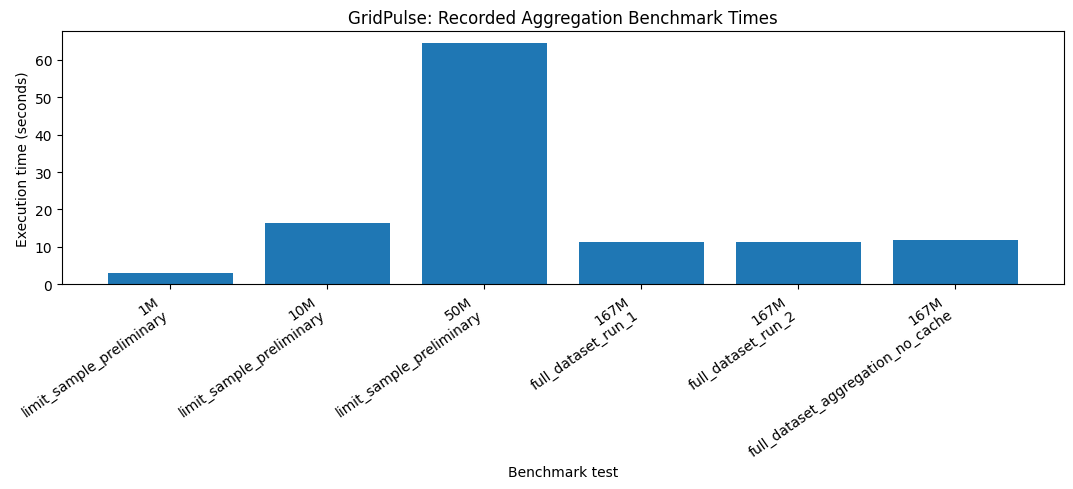

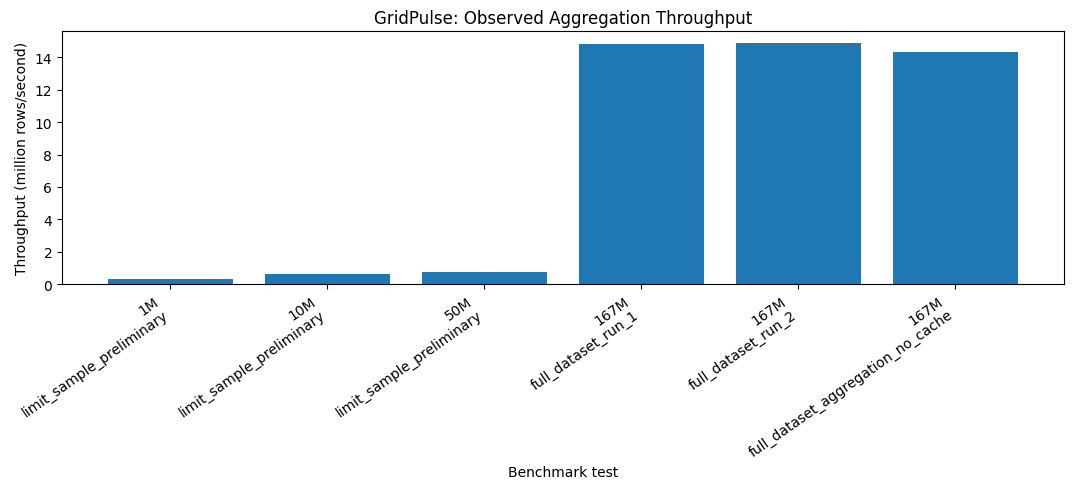


FILES SAVED
Summary: /content/drive/MyDrive/GridPulse_outputs/direct_spark_run/benchmarks/scalability_summary.csv
Execution-time graph: /content/drive/MyDrive/GridPulse_outputs/direct_spark_run/benchmarks/benchmark_execution_time.png
Throughput graph: /content/drive/MyDrive/GridPulse_outputs/direct_spark_run/benchmarks/benchmark_throughput.png


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Existing benchmark file
benchmark_dir = ROOT / "benchmarks"
csv_path = benchmark_dir / "spark_baseline_results.csv"

df = pd.read_csv(csv_path)

# Display all recorded benchmark results
print("GRIDPULSE SCALABILITY BENCHMARK")
print("=" * 60)
display(df)

# Create a report-friendly summary
summary = (
    df.groupby("benchmark_type", as_index=False)
      .agg(
          number_of_runs=("elapsed_seconds", "count"),
          rows_processed=("dataset_size", "max"),
          average_time_seconds=("elapsed_seconds", "mean"),
          average_throughput=("throughput_rows_per_second", "mean")
      )
)

summary["average_time_seconds"] = summary["average_time_seconds"].round(2)
summary["average_throughput"] = summary["average_throughput"].round(0).astype("int64")

print("\nSUMMARY BY BENCHMARK TYPE")
display(summary)

# Save summary
summary_path = benchmark_dir / "scalability_summary.csv"
summary.to_csv(summary_path, index=False)

# Graph 1: execution time by recorded test
plt.figure(figsize=(11, 5))
labels = [
    f"{int(row.dataset_size / 1_000_000)}M\n{row.benchmark_type}"
    for row in df.itertuples()
]
plt.bar(labels, df["elapsed_seconds"])
plt.ylabel("Execution time (seconds)")
plt.xlabel("Benchmark test")
plt.title("GridPulse: Recorded Aggregation Benchmark Times")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

time_graph_path = benchmark_dir / "benchmark_execution_time.png"
plt.savefig(time_graph_path, dpi=200, bbox_inches="tight")
plt.show()

# Graph 2: observed throughput by recorded test
plt.figure(figsize=(11, 5))
plt.bar(labels, df["throughput_rows_per_second"] / 1_000_000)
plt.ylabel("Throughput (million rows/second)")
plt.xlabel("Benchmark test")
plt.title("GridPulse: Observed Aggregation Throughput")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

throughput_graph_path = benchmark_dir / "benchmark_throughput.png"
plt.savefig(throughput_graph_path, dpi=200, bbox_inches="tight")
plt.show()

print("\nFILES SAVED")
print("Summary:", summary_path)
print("Execution-time graph:", time_graph_path)
print("Throughput graph:", throughput_graph_path)


In [ ]:
import pandas as pd

benchmark_file = ROOT / "benchmarks" / "spark_baseline_results.csv"
df = pd.read_csv(benchmark_file)

print("BENCHMARK RECORDS")
display(df)

print("\nFULL-DATASET RUNS")
full_runs = df[
    df["benchmark_type"].str.startswith("full_dataset")
].copy()

display(full_runs)

if not full_runs.empty:
    print("\nFULL-DATASET PERFORMANCE SUMMARY")
    print(f"Number of recorded runs: {len(full_runs)}")
    print(
        "Mean time: "
        f"{full_runs['elapsed_seconds'].mean():.2f} seconds"
    )
    print(
        "Mean observed throughput: "
        f"{full_runs['throughput_rows_per_second'].mean():,.0f} rows/second"
    )

BENCHMARK RECORDS


,dataset_size,elapsed_seconds,throughput_rows_per_second,benchmark_type
0,1000000,3.02,330899,limit_sample_preliminary
1,10000000,16.45,608009,limit_sample_preliminary
2,50000000,64.37,776799,limit_sample_preliminary
3,167811461,11.32,14819157,full_dataset_run_1
4,167811461,11.30,14852796,full_dataset_run_2
5,167811461,11.73,14303819,full_dataset_aggregation_no_cache



FULL-DATASET RUNS


,dataset_size,elapsed_seconds,throughput_rows_per_second,benchmark_type
3,167811461,11.32,14819157,full_dataset_run_1
4,167811461,11.30,14852796,full_dataset_run_2
5,167811461,11.73,14303819,full_dataset_aggregation_no_cache



FULL-DATASET PERFORMANCE SUMMARY
Number of recorded runs: 3
Mean time: 11.45 seconds
Mean observed throughput: 14,658,591 rows/second


In [ ]:
from pathlib import Path

output_paths = {
    "Cleaned Silver": ROOT / "silver/energy",
    "Rejected records": ROOT / "quality/rejected",
    "Deduplicated Silver": ROOT / "silver/energy_deduplicated",
    "Hourly Gold": ROOT / "gold_deduplicated/hourly_consumption",
    "Daily Gold": ROOT / "gold_deduplicated/daily_consumption",
    "Household Gold": ROOT / "gold_deduplicated/household_summary",
    "Hourly features": ROOT / "features/hourly_features",
    "Daily features": ROOT / "features/daily_features",
    "Forecast features": ROOT / "features/forecast_features",
}

print("GRIDPULSE OUTPUT VALIDATION")
print("=" * 55)

for name, path in output_paths.items():
    exists = path.exists()
    has_parquet = (
        exists
        and any(path.rglob("*.parquet"))
    )

    print(
        f"{name:24} | "
        f"{'EXISTS' if exists else 'MISSING':7} | "
        f"{'PARQUET FOUND' if has_parquet else 'NO PARQUET FOUND'}"
    )

GRIDPULSE OUTPUT VALIDATION
Cleaned Silver           | EXISTS  | PARQUET FOUND
Rejected records         | EXISTS  | PARQUET FOUND
Deduplicated Silver      | EXISTS  | PARQUET FOUND
Hourly Gold              | EXISTS  | PARQUET FOUND
Daily Gold               | EXISTS  | PARQUET FOUND
Household Gold           | EXISTS  | PARQUET FOUND
Hourly features          | EXISTS  | PARQUET FOUND
Daily features           | EXISTS  | PARQUET FOUND
Forecast features        | EXISTS  | PARQUET FOUND


In [ ]:

from pyspark.sql import functions as F

paths = {
    "silver": ROOT / "silver/energy",
    "rejected": ROOT / "quality/rejected",
    "deduplicated": ROOT / "silver/energy_deduplicated",
    "hourly_gold": ROOT / "gold_deduplicated/hourly_consumption",
    "daily_gold": ROOT / "gold_deduplicated/daily_consumption",
    "household_gold": ROOT / "gold_deduplicated/household_summary",
    "hourly_features": ROOT / "features/hourly_features",
    "daily_features": ROOT / "features/daily_features",
    "forecast_features": ROOT / "features/forecast_features",
}

dfs = {
    name: spark.read.parquet(str(path))
    for name, path in paths.items()
}

print("GRIDPULSE DATA QUALITY VALIDATION")
print("=" * 55)

# Count rows in each saved dataset
for name, df in dfs.items():
    print(f"{name:20} : {df.count():,} rows")

# Reconcile source rows
silver_count = dfs["silver"].count()
rejected_count = dfs["rejected"].count()
deduplicated_count = dfs["deduplicated"].count()

print("\nROW-COUNT RECONCILIATION")
print("Silver + rejected:", f"{silver_count + rejected_count:,}")
print("Silver before deduplication:", f"{silver_count:,}")
print("Rows removed by deduplication:",
      f"{silver_count - deduplicated_count:,}")

# Check exact duplicate groups in deduplicated Silver
dedup_df = dfs["deduplicated"]

duplicate_groups = (
    dedup_df
    .groupBy(
        "household_id",
        "reading_time",
        "energy_kwh_half_hour",
        "tariff_type"
    )
    .count()
    .filter(F.col("count") > 1)
    .count()
)

print("\nREMAINING EXACT DUPLICATE GROUPS:",
      f"{duplicate_groups:,}")

# Check whether hourly and daily aggregates reconcile
hourly_total = dfs["hourly_gold"].agg(
    F.sum("total_energy_kwh")
).first()[0]

daily_total = dfs["daily_gold"].agg(
    F.sum("total_energy_kwh")
).first()[0]

print("\nENERGY TOTAL RECONCILIATION")
print("Hourly Gold total:", hourly_total)
print("Daily Gold total:", daily_total)
print("Absolute difference:",
      abs((hourly_total or 0) - (daily_total or 0)))


GRIDPULSE DATA QUALITY VALIDATION
silver               : 167,926,914 rows
rejected             : 5,560 rows
deduplicated         : 167,811,461 rows
hourly_gold          : 83,925,571 rows
daily_gold           : 3,510,403 rows
household_gold       : 5,561 rows
hourly_features      : 83,925,571 rows
daily_features       : 3,510,403 rows
forecast_features    : 3,510,403 rows

ROW-COUNT RECONCILIATION
Silver + rejected: 167,932,474
Silver before deduplication: 167,926,914
Rows removed by deduplication: 115,453

REMAINING EXACT DUPLICATE GROUPS: 0

ENERGY TOTAL RECONCILIATION
Hourly Gold total: 35539823.3063847
Daily Gold total: 35539823.30638556
Absolute difference: 8.642673492431641e-07


In [ ]:

print("HOURLY FEATURES")
dfs["hourly_features"].printSchema()
dfs["hourly_features"].select(
    "household_id",
    "hour",
    "hour_of_day",
    "day_of_week",
    "is_weekend",
    "is_peak_hour"
).show(10, truncate=False)

print("\nDAILY FEATURES")
dfs["daily_features"].printSchema()
dfs["daily_features"].select(
    "household_id",
    "date",
    "day_of_week",
    "is_weekend",
    "month",
    "year"
).show(10, truncate=False)

print("\nFORECAST FEATURES")
dfs["forecast_features"].printSchema()
dfs["forecast_features"].select(
    "household_id",
    "date",
    "total_energy_kwh",
    "previous_observation_date",
    "previous_day_consumption_kwh",
    "days_since_previous_observation",
    "consumption_change_kwh",
    "previous_7_observation_avg_kwh"
).show(10, truncate=False)


HOURLY FEATURES
root
 |-- household_id: string (nullable = true)
 |-- hour: timestamp (nullable = true)
 |-- tariff_type: string (nullable = true)
 |-- total_energy_kwh: double (nullable = true)
 |-- average_half_hour_kwh: double (nullable = true)
 |-- reading_count: long (nullable = true)
 |-- peak_half_hour_kwh: double (nullable = true)
 |-- hour_of_day: integer (nullable = true)
 |-- day_of_week: integer (nullable = true)
 |-- is_weekend: boolean (nullable = true)
 |-- month: integer (nullable = true)
 |-- is_peak_hour: boolean (nullable = true)

+------------+-------------------+-----------+-----------+----------+------------+
|household_id|hour               |hour_of_day|day_of_week|is_weekend|is_peak_hour|
+------------+-------------------+-----------+-----------+----------+------------+
|MAC000002   |2012-10-12 17:00:00|17         |6          |false     |true        |
|MAC000002   |2012-10-12 23:00:00|23         |6          |false     |false       |
|MAC000002   |2012-10-13 09:0

In [ ]:

from pyspark.sql import functions as F

hourly = dfs["hourly_features"]
daily = dfs["daily_features"]
forecast = dfs["forecast_features"]

# 1. Hourly feature checks
hourly_errors = hourly.filter(
    (F.col("hour_of_day") != F.hour("hour")) |
    (F.col("day_of_week") != F.dayofweek("hour")) |
    (F.col("month") != F.month("hour")) |
    (F.col("is_weekend") != F.dayofweek("hour").isin(1, 7)) |
    (F.col("is_peak_hour") != F.hour("hour").between(17, 20))
).count()

# 2. Daily feature checks
daily_errors = daily.filter(
    (F.col("day_of_week") != F.dayofweek("date")) |
    (F.col("is_weekend") != F.dayofweek("date").isin(1, 7)) |
    (F.col("month") != F.month("date")) |
    (F.col("year") != F.year("date")) |
    (F.col("day_of_month") != F.dayofmonth("date"))
).count()

# 3. Forecast arithmetic check
forecast_errors = forecast.filter(
    F.col("previous_observation_date").isNotNull() &
    (
        (F.col("days_since_previous_observation") != F.datediff(
            "date", "previous_observation_date"
        )) |
        (
            F.abs(
                F.col("consumption_change_kwh") -
                (
                    F.col("total_energy_kwh") -
                    F.col("previous_day_consumption_kwh")
                )
            ) > 1e-6
        )
    )
).count()

print("FEATURE VALIDATION")
print("=" * 45)
print("Hourly feature errors:", f"{hourly_errors:,}")
print("Daily feature errors:", f"{daily_errors:,}")
print("Forecast arithmetic/date errors:", f"{forecast_errors:,}")

if hourly_errors == 0 and daily_errors == 0 and forecast_errors == 0:
    print("\nAll tested feature rules passed.")
else:
    print("\nSome feature rules failed; investigate before finalizing.")


FEATURE VALIDATION
Hourly feature errors: 0
Daily feature errors: 0
Forecast arithmetic/date errors: 0

All tested feature rules passed.
